# Experiment 1 — Time and Frequency Domain Analysis and Pendulum Simulation

**Course:** CSAI4014 — AISR Laboratory  
**Student:** Naman Chanana  
**SAP ID:** 500119485  
**Roll No.:** R2142230993  
**Batch:** 2 — AI & ML  
**Lab Partner:** None

## Aim
To study time- and frequency-domain signal analysis using FFT, demonstrate spectral leakage and aliasing, and simulate a damped nonlinear pendulum including its phase portrait and amplitude-dependent period.

All figures generated during the run are saved in `figs/`, and numerical results are saved in `results.json`. No external dataset is required.


In [1]:
import json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figs", exist_ok=True)
RESULTS = {}                      # every number the report quotes is stored here

def save(fig, name):
    """Save a figure into figs/ (150 dpi PNG, as the report guidelines ask)."""
    fig.savefig(os.path.join("figs", name), bbox_inches="tight")

def env_info():
    info = {"python": platform.python_version(), "numpy": np.__version__,
            "matplotlib": matplotlib.__version__, "os": f"{platform.system()} {platform.release()}",
            "cpu": platform.processor() or platform.machine()}
    try:
        import scipy; info["scipy"] = scipy.__version__
    except ImportError:
        pass
    return info

RESULTS["env"] = env_info()
print(RESULTS["env"])

{'python': '3.13.18', 'numpy': '2.4.6', 'matplotlib': '3.10.0', 'os': 'Linux 6.6.159+', 'cpu': 'x86_64', 'scipy': '1.16.3'}


## 1. Building a signal and reading its spectrum

In [2]:
fs, T = 500.0, 2.0                 # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1/fs)
N = t.size                         # N = 1000 samples
df, f_nyq = fs/N, fs/2

COMPONENTS = [(5, 1.00), (20, 0.50), (50, 0.25)]   # (frequency Hz, amplitude)
rng = np.random.default_rng(0)     # seeded: the result is reproducible
x = sum(a*np.sin(2*np.pi*f0*t) for f0, a in COMPONENTS) + 0.20*rng.standard_normal(N)

def amplitude_spectrum(sig, fs):
    """One-sided amplitude spectrum scaled so peak height = sinusoid amplitude."""
    X = np.fft.rfft(sig)                      # real input -> one-sided spectrum
    f = np.fft.rfftfreq(sig.size, d=1/fs)     # matching frequency axis in Hz
    amp = np.abs(X) * 2.0 / sig.size          # amplitudes in the units of the signal
    amp[0] /= 2.0                             # the zero-frequency term is not doubled
    return f, amp

f, amp = amplitude_spectrum(x, fs)
print(f"N = {N}, resolution df = {df} Hz, Nyquist = {f_nyq} Hz")
print("peaks at:", np.round(f[amp > 0.1], 2), "Hz")

measured = []
for f0, a in COMPONENTS:
    k = np.argmin(np.abs(f - f0))
    k = k - 2 + np.argmax(amp[k-2:k+3])       # strongest bin near the set frequency
    measured.append({"set_f": f0, "meas_f": float(f[k]), "set_a": a, "meas_a": float(amp[k])})
    print(f"set {f0:>3} Hz, {a:.2f}  ->  measured {f[k]:5.1f} Hz, {amp[k]:.3f}")
RESULTS["sampling"] = {"fs": fs, "T": T, "N": N, "df": df, "nyquist": f_nyq}
RESULTS["spectrum"] = measured

N = 1000, resolution df = 0.5 Hz, Nyquist = 250.0 Hz
peaks at: [ 5. 20. 50.] Hz
set   5 Hz, 1.00  ->  measured   5.0 Hz, 1.008
set  20 Hz, 0.50  ->  measured  20.0 Hz, 0.492
set  50 Hz, 0.25  ->  measured  50.0 Hz, 0.252


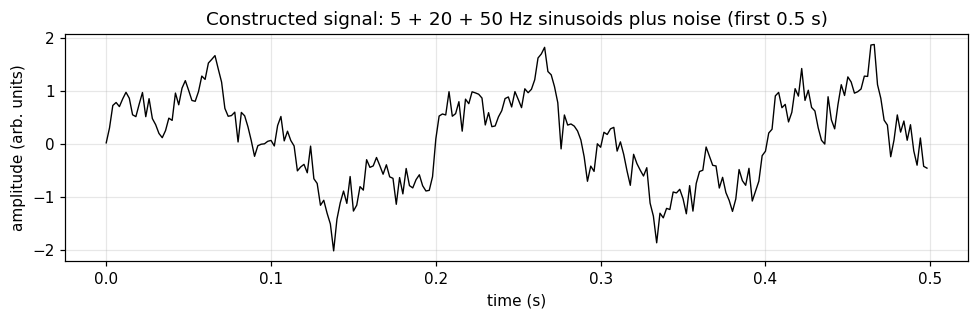

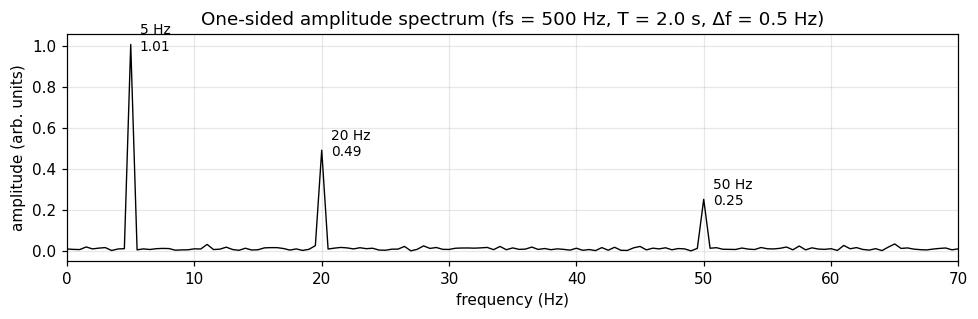

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
m = t < 0.5
ax.plot(t[m], x[m], lw=0.9, color="k")
ax.set(xlabel="time (s)", ylabel="amplitude (arb. units)",
       title="Constructed signal: 5 + 20 + 50 Hz sinusoids plus noise (first 0.5 s)")
fig.tight_layout(); save(fig, "fig1_1_signal_time.png"); plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(f, amp, lw=0.9, color="k")
for d in measured:
    ax.annotate(f"{d['meas_f']:.0f} Hz\n{d['meas_a']:.2f}", (d["meas_f"], d["meas_a"]),
                xytext=(6, -4), textcoords="offset points", fontsize=9)
ax.set(xlim=(0, 70), xlabel="frequency (Hz)", ylabel="amplitude (arb. units)",
       title=f"One-sided amplitude spectrum (fs = {fs:.0f} Hz, T = {T} s, Δf = {df} Hz)")
fig.tight_layout(); save(fig, "fig1_2_spectrum.png"); plt.show()

## 2. Spectral leakage (T = 1.7 s)
With T = 1.7 s the resolution is Δf = 1/1.7 ≈ 0.588 Hz, so 5, 20 and 50 Hz no longer fall on bins.

In [4]:
T_l = 1.7
t_l = np.arange(0, T_l, 1/fs)
x_l = sum(a*np.sin(2*np.pi*f0*t_l) for f0, a in COMPONENTS)    # noise-free, to isolate leakage
f_l, amp_l = amplitude_spectrum(x_l, fs)
leak = []
for f0, a in COMPONENTS:
    k = np.argmin(np.abs(f_l - f0)); k = k - 2 + np.argmax(amp_l[k-2:k+3])
    spread = int(np.sum(amp_l[k-5:k+6] > 0.05*a))           # bins above 5 % of the true amplitude
    leak.append({"set_f": f0, "peak_f": float(f_l[k]), "peak_a": float(amp_l[k]), "bins_above_5pct": spread})
    print(f"{f0:>3} Hz: peak at {f_l[k]:.3f} Hz, height {amp_l[k]:.3f} (true {a}), "
          f"{spread} bins above 5% of true amplitude")
RESULTS["leakage"] = {"T": T_l, "df": fs/t_l.size, "peaks": leak}

  5 Hz: peak at 4.706 Hz, height 0.656 (true 1.0), 11 bins above 5% of true amplitude
 20 Hz: peak at 20.000 Hz, height 0.500 (true 0.5), 1 bins above 5% of true amplitude
 50 Hz: peak at 50.000 Hz, height 0.250 (true 0.25), 1 bins above 5% of true amplitude


## 3. Aliasing: a 5 Hz sine sampled at 8 Hz

Nyquist = 4.0 Hz;  peak at: 3.0 Hz  (expected |8 - 5| = 3 Hz)


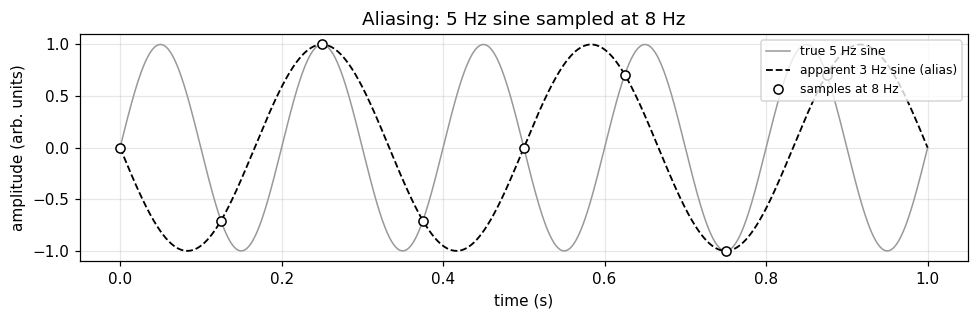

In [5]:
fs_a = 8.0                          # deliberately below 2 x 5 Hz
t_a = np.arange(0, 1.0, 1/fs_a)
x_a = np.sin(2*np.pi*5*t_a)         # a 5 Hz sine, undersampled
X_a = np.fft.rfft(x_a)
f_a = np.fft.rfftfreq(t_a.size, d=1/fs_a)
alias = float(f_a[np.argmax(np.abs(X_a))])
print("Nyquist =", fs_a/2, "Hz;  peak at:", alias, "Hz  (expected |8 - 5| = 3 Hz)")
RESULTS["alias_peak_hz"] = alias

tc = np.linspace(0, 1, 2000)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(tc, np.sin(2*np.pi*5*tc), lw=1, color="0.6", label="true 5 Hz sine")
ax.plot(tc, -np.sin(2*np.pi*3*tc), "--", lw=1.2, color="k", label="apparent 3 Hz sine (alias)")
ax.plot(t_a, x_a, "o", ms=6, mfc="w", mec="k", label="samples at 8 Hz")
ax.set(xlabel="time (s)", ylabel="amplitude (arb. units)", title="Aliasing: 5 Hz sine sampled at 8 Hz")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); save(fig, "fig1_3_aliasing.png"); plt.show()

## 4. The pendulum

T0 = 2.0061 s


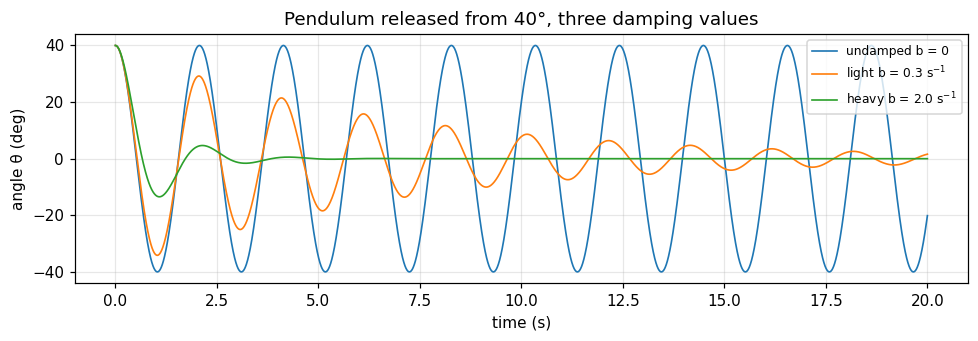

In [6]:
from scipy.integrate import solve_ivp
g, L = 9.81, 1.0

def pendulum(t, y, b):              # signature (t, y) as solve_ivp requires
    theta, omega = y
    return [omega, -b*omega - (g/L)*np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0],
                    args=(b,), t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

T0 = 2*np.pi*np.sqrt(L/g)           # small-angle prediction
print("T0 =", round(T0, 4), "s")
RESULTS["T0"] = T0

DAMPING = [0.0, 0.3, 2.0]           # b/m in 1/s
labels = {0.0: "undamped b = 0", 0.3: "light b = 0.3 s$^{-1}$", 2.0: "heavy b = 2.0 s$^{-1}$"}
runs = {b: simulate(40, b) for b in DAMPING}
RESULTS["damping"] = DAMPING

fig, ax = plt.subplots(figsize=(9, 3.2))
for b, (tt, th, _) in runs.items():
    ax.plot(tt, np.rad2deg(th), lw=1.1, label=labels[b])
ax.set(xlabel="time (s)", ylabel="angle θ (deg)", title="Pendulum released from 40°, three damping values")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); save(fig, "fig1_4_damping.png"); plt.show()

In [7]:
def period_zero_crossings(tt, th):
    """Mean interval between upward zero crossings, linearly interpolated in time."""
    i = np.where((th[:-1] < 0) & (th[1:] >= 0))[0]
    tc = tt[i] - th[i]*(tt[i+1]-tt[i])/(th[i+1]-th[i])
    return float(np.mean(np.diff(tc)))

def period_spectrum(tt, th):
    fs2 = 1/(tt[1]-tt[0])
    A = np.abs(np.fft.rfft(th)); fr = np.fft.rfftfreq(th.size, 1/fs2)
    return float(1/fr[1:][np.argmax(A[1:])])  # skip bin 0: it holds the mean

rows = []
for a in (5, 45, 95, 135, 175):
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    pz, ps = period_zero_crossings(tt, th), period_spectrum(tt, th)
    rows.append({"theta0": a, "zero_cross": pz, "spectrum": ps, "ratio": pz/T0})
    print(f"{a:>4} deg: zero crossings {pz:.3f} s, spectrum {ps:.3f} s, ratio {pz/T0:.2f}")
RESULTS["period_table"] = rows
r5 = rows[0]
RESULTS["err5_zero_pct"] = 100*(r5["zero_cross"]-T0)/T0
RESULTS["err5_spec_pct"] = 100*(r5["spectrum"]-T0)/T0
print(f"5 deg errors vs T0: zero crossings {RESULTS['err5_zero_pct']:+.3f} %, "
      f"spectrum {RESULTS['err5_spec_pct']:+.3f} %")

   5 deg: zero crossings 2.007 s, spectrum 2.000 s, ratio 1.00
  45 deg: zero crossings 2.086 s, spectrum 2.069 s, ratio 1.04
  95 deg: zero crossings 2.417 s, spectrum 2.400 s, ratio 1.21
 135 deg: zero crossings 3.065 s, spectrum 3.000 s, ratio 1.53
 175 deg: zero crossings 5.773 s, spectrum 6.001 s, ratio 2.88
5 deg errors vs T0: zero crossings +0.048 %, spectrum -0.294 %


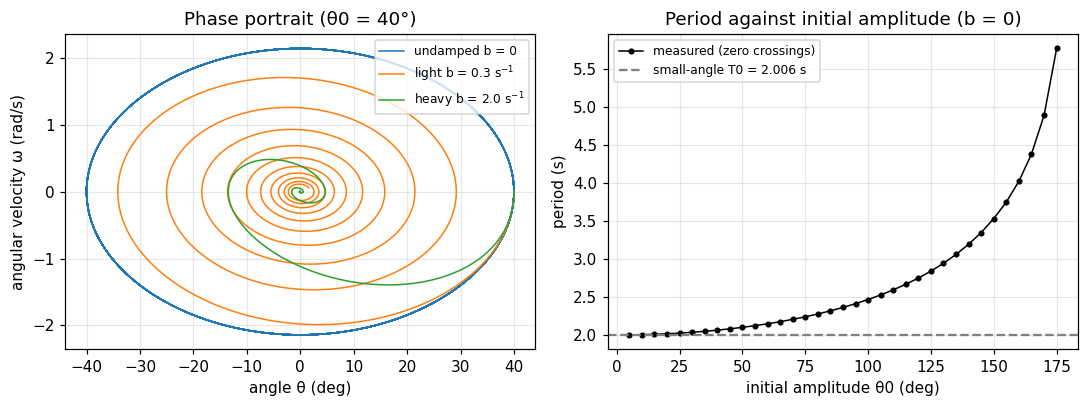

period exceeds T0 by 1 % above 25 deg and by 5 % above 55 deg


In [8]:
amps = np.arange(5, 180, 5)
periods = [period_zero_crossings(*simulate(a, 0.0, T=60.0, n=12000)[:2]) for a in amps]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
for b, (tt, th, om) in runs.items():
    ax1.plot(np.rad2deg(th), om, lw=1, label=labels[b])
ax1.set(xlabel="angle θ (deg)", ylabel="angular velocity ω (rad/s)", title="Phase portrait (θ0 = 40°)")
ax1.legend(fontsize=8)
ax2.plot(amps, periods, "o-", ms=3, lw=1, color="k", label="measured (zero crossings)")
ax2.axhline(T0, ls="--", color="0.5", label=f"small-angle T0 = {T0:.3f} s")
ax2.set(xlabel="initial amplitude θ0 (deg)", ylabel="period (s)", title="Period against initial amplitude (b = 0)")
ax2.legend(fontsize=8)
fig.tight_layout(); save(fig, "fig1_5_phase_period.png"); plt.show()
RESULTS["period_sweep"] = {"amps": amps.tolist(), "periods": periods}
# where does the small-angle formula stop being within 1 % / 5 %?
RESULTS["amp_1pct"] = int(amps[np.argmax(np.array(periods) > 1.01*T0)])
RESULTS["amp_5pct"] = int(amps[np.argmax(np.array(periods) > 1.05*T0)])
print("period exceeds T0 by 1 % above", RESULTS["amp_1pct"], "deg and by 5 % above", RESULTS["amp_5pct"], "deg")

In [9]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("saved results.json and", len(os.listdir("figs")), "figures in figs/")

saved results.json and 5 figures in figs/


## Conclusion

This experiment demonstrates how FFT reveals frequency components of a sampled signal, how non-bin-aligned frequencies cause spectral leakage, and how undersampling causes aliasing. The pendulum simulation shows the effect of damping and the nonlinear increase in oscillation period at large initial angles.
